# Blackjack enhancement 2: momentum-accelerated KL-SPMD with dynamic TOMC

**IE 692 course project.** Same simplified Blackjack MDP as the baseline (cards 2-5 with
replacement, dealer draws to 9+, bust above 11, gamma = 0.9).

The baseline's dynamic episodic TOMC estimator is unchanged. Only the policy update changes:

$$B_k(s,a)=\mathbf 1\{(s,a)\in\mathcal E_k\cap\mathcal E_{k-1}\},\qquad
  M_k=\widehat Q_k+\lambda\,B_k\odot(\widehat Q_k-\widehat Q_{k-1}),$$
$$\pi_{k+1}(a\mid s)\propto\pi_k(a\mid s)\exp[-\eta M_k(s,a)].$$

$\mathcal E_k$ is the TOMC-eligible set ($\pi_k(a\mid s)\ge0.05$). Momentum uses the previous
**raw** estimate $\widehat Q_{k-1}$ (never the previous $M$), only on pairs eligible in both
iterations, and is zero at the first iteration. With $\lambda=0$ the update is the baseline's.

What is run:
1. **Checks.** Baseline estimator, KL update, momentum mask (all four eligibility cases),
   equivalence with the baseline at lambda = 0, RNG independence, exact model.
2. **Tuning.** Enhancement 2: eta x lambda = 9 configurations; for every lambda, eta is tuned
   separately (its own row of the sweep). Baseline: eta (same candidates). 10% of the
   budget per configuration, tuning seed 100.
3. **Full runs.** The unchanged baseline and every lambda at its tuned eta,
   `SAMPLE_BUDGET` training observations each, seeds 0-4.
4. **Evaluation (never used for training).** Exact Bellman V^pi and 500 independent test games
   per evaluated policy (about 200 checkpoints at most), aligned by training observations.
5. **Plots.** The baseline and every lambda together (value with training times, loss rate,
   policy updates) and a tuning summary.

**How to run:** `python blackjack_enhancement2.py` (or the `# %%` cells in VS Code / Jupyter).
Self-contained. Dependencies: NumPy, pandas, Matplotlib. Figures go to `figures/`,
results to `results/`.

In [1]:
# 1. Settings
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter, MaxNLocator

GAMMA = 0.9
MIN_SUFFIX_STEPS = 100                    # Batch ends once every eligible pair has L(s,a) >= 100.
SAMPLE_BUDGET = 400_000                   # Training observations per run (same for both methods).
TUNING_BUDGET = SAMPLE_BUDGET // 10       # 10% of the budget = 40,000 observations per configuration.
SEEDS = (0, 1, 2, 3, 4)                   # Five independent full runs.
TUNING_SEED = 100                         # Tuning uses its own seed, separate from the full runs.
TEST_GAMES = 500                          # Independent loss-rate evaluation games per policy.
N_CHECKPOINTS = 200                       # At most about 200 evaluated policies per run.

ETA_CANDIDATES = (0.1, 1.0, 10.0)         # Policy stepsize (both methods).
LAMBDA_CANDIDATES = (0.5, 1.0, 10.0)      # Momentum strength (Enhancement 2).
TIE_TOLERANCE = 1e-6                      # Gaps at (8, 4) closer than this count as tied.

CARD_VALUES = (2, 3, 4, 5)                # Infinite deck, drawn with replacement.
BUST_LIMIT = 11                           # A sum above 11 is a bust.
DEALER_STANDS_AT = 9                      # Dealer draws until the sum is 9 or more.
WIN, DRAW, LOSS = -1.0, 0.0, 1.0          # Costs to minimize.

PLAYER_SUMS = range(4, 12)                # 8 player sums (4..11)
DEALER_CARDS = range(2, 6)                # 4 dealer up-cards (2..5)
N_STATES, N_ACTIONS = 32, 2               # All 32 states kept; none excluded as unreachable.
STICK, HIT = 0, 1
PI_THRESHOLD = (1 - GAMMA) / N_ACTIONS    # 0.05: pairs below it get the pessimistic fallback.
FALLBACK_Q = 1 / (1 - GAMMA)              # 10.0


def state2ID(player_sum, dealer_card):
    """Map (player sum 4..11, dealer card 2..5) to a state index 0..31."""
    return (player_sum - 4) * 4 + (dealer_card - 2)


REF_PLAYER_SUM, REF_DEALER_CARD = 8, 4
REPORT_STATE = state2ID(REF_PLAYER_SUM, REF_DEALER_CARD)
REPORT_LABEL = f"({REF_PLAYER_SUM}, {REF_DEALER_CARD})"
UNIFORM_POLICY = np.full((N_STATES, N_ACTIONS), 1 / N_ACTIONS)

# Plot style shared with the baseline, Enhancement 1 and the GridWorld notebooks.
BASELINE_COLOR = "#6f6e69"
ENH_COLOR = "#eb6834"                     # GridWorld second series color (Enhancement 1 is blue).
LAMBDA_COLORS = dict(zip(LAMBDA_CANDIDATES, (ENH_COLOR, "#2f9e6e", "#8a5cc2", "#2a78d6", "#c2a03a")))
INK = "#0b0b0b"
MUTED = "#52514e"
BACKGROUND = "#fcfcfb"
GRID_COLOR = "#e6e5e0"
FIGURES, RESULTS = Path("figures"), Path("results")

## 2. Environment (copied unchanged from the baseline)

In [2]:
class RandomStream:
    """Buffered cards and uniforms from one seeded NumPy generator."""

    def __init__(self, rng, block=1 << 16):
        self.rng, self.block = rng, block
        self._cards, self._uniforms = [], []

    def card(self):
        if not self._cards:
            self._cards = self.rng.choice(CARD_VALUES, size=self.block).tolist()
        return self._cards.pop()

    def uniform(self):
        if not self._uniforms:
            self._uniforms = self.rng.random(self.block).tolist()
        return self._uniforms.pop()


def stick_cost(player_sum, dealer_card, stream):
    """Dealer draws to DEALER_STANDS_AT or more; return the player's terminal cost."""
    dealer_sum = dealer_card
    while dealer_sum < DEALER_STANDS_AT:
        dealer_sum += stream.card()
    if dealer_sum > BUST_LIMIT or player_sum > dealer_sum:
        return WIN
    return LOSS if player_sum < dealer_sum else DRAW


def play_hand(hit_prob, stream):
    """One complete hand. hit_prob[s] = pi(HIT | s). Returns (states, actions, costs)."""
    player_sum = stream.card() + stream.card()
    dealer_card = stream.card()
    states, actions, costs = [], [], []
    while True:
        state = state2ID(player_sum, dealer_card)
        states.append(state)
        if stream.uniform() < hit_prob[state]:
            actions.append(HIT)
            player_sum += stream.card()
            if player_sum > BUST_LIMIT:
                costs.append(LOSS)
                return states, actions, costs
            costs.append(0.0)
        else:
            actions.append(STICK)
            costs.append(stick_cost(player_sum, dealer_card, stream))
            return states, actions, costs

## 3. Baseline: dynamic episodic TOMC + KL-SPMD (copied unchanged)

Freeze the policy, play hands until every eligible pair has $L(s,a)\ge100$ suffix steps,
average every complete discounted return into $\widehat Q$ (fallback $1/(1-\gamma)$ for
ineligible pairs), then one KL-SPMD update. If the budget runs out mid-batch, the current
hand is finished and the incomplete batch gives no update.

In [3]:
def empty_batch():
    pairs = N_STATES * N_ACTIONS
    return {"return_sum": [0.0] * pairs, "return_count": [0] * pairs, "suffix_steps": [0] * pairs}


def add_hand(batch, states, actions, costs, gamma, eligible, min_steps):
    """Add every complete return of one hand; return how many eligible pairs just reached min_steps."""
    hand_length, G, newly_complete = len(costs), 0.0, 0
    for t in range(hand_length - 1, -1, -1):
        G = costs[t] + gamma * G
        pair = states[t] * N_ACTIONS + actions[t]
        before = batch["suffix_steps"][pair]
        batch["suffix_steps"][pair] += hand_length - t
        batch["return_sum"][pair] += G
        batch["return_count"][pair] += 1
        if eligible[pair] and before < min_steps <= batch["suffix_steps"][pair]:
            newly_complete += 1
    return newly_complete


def collect_batch(policy, stream, gamma=GAMMA, min_steps=MIN_SUFFIX_STEPS,
                  observations_left=np.inf):
    """Play hands under the frozen policy until all eligible pairs have L >= min_steps."""
    eligible_mask = policy >= PI_THRESHOLD
    eligible = eligible_mask.ravel().tolist()
    hit_prob = policy[:, HIT].tolist()
    batch, missing, observations, hands = empty_batch(), int(eligible_mask.sum()), 0, 0

    while missing > 0 and observations < observations_left:
        states, actions, costs = play_hand(hit_prob, stream)
        missing -= add_hand(batch, states, actions, costs, gamma, eligible, min_steps)
        observations += len(costs)
        hands += 1

    counts = np.array(batch["return_count"]).reshape(policy.shape)
    steps = np.array(batch["suffix_steps"]).reshape(policy.shape)
    sums = np.array(batch["return_sum"]).reshape(policy.shape)
    q_hat = np.full(policy.shape, FALLBACK_Q)
    q_hat[eligible_mask] = sums[eligible_mask] / np.maximum(counts[eligible_mask], 1)
    return {"q_hat": q_hat, "complete": missing == 0, "observations": observations,
            "hands": hands, "return_count": counts, "suffix_steps": steps,
            "eligible": eligible_mask}


def kl_spmd_update(policy, q_hat, eta):
    scores = -eta * q_hat
    scores -= scores.max(axis=1, keepdims=True)
    weights = policy * np.exp(scores)
    return weights / weights.sum(axis=1, keepdims=True)


def run_spmd(max_observations, eta, seed, verbose=False):
    """Baseline: KL-SPMD + episodic TOMC until the training observation budget is used."""
    train_seed, test_seed = np.random.SeedSequence(seed).spawn(2)
    stream = RandomStream(np.random.default_rng(train_seed))
    policy = UNIFORM_POLICY.copy()
    policies, samples, records = [policy.copy()], [0], []
    used = 0
    started = time.perf_counter()

    while used < max_observations:
        batch = collect_batch(policy, stream, observations_left=max_observations - used)
        used += batch["observations"]
        if not batch["complete"]:
            break                                    # Budget ran out mid-batch: no update.
        records.append({
            "observations": batch["observations"],
            "cumulative_observations": used,
            "min_eligible_L": int(batch["suffix_steps"][batch["eligible"]].min()),
            "value_estimate": float(policy[REPORT_STATE] @ batch["q_hat"][REPORT_STATE]),
        })
        policy = kl_spmd_update(policy, batch["q_hat"], eta)
        policies.append(policy.copy())
        samples.append(used)

    seconds = time.perf_counter() - started
    if verbose:
        print(f"Baseline eta={eta:g}, seed={seed} | {len(records)} updates, {used:,} observations, "
              f"{seconds:.1f} s", flush=True)
    return {"seed": seed, "eta": eta, "policies": np.array(policies),
            "samples": np.array(samples), "history": pd.DataFrame(records, columns=[
                "observations", "cumulative_observations", "min_eligible_L", "value_estimate"]),
            "total_observations": used, "seconds": seconds, "test_seed": test_seed}

## 4. Enhancement 2: masked momentum in the KL update

Same batches, same TOMC estimates and same stopping rule as the baseline. The only new
step builds $M_k$ before the KL update. The tables needed to verify every update are kept.

In [4]:
def momentum_q_table(q_hat, q_previous, eligible, eligible_previous, lam):
    """M_k = Q_k + lam * (Q_k - Q_{k-1}) on pairs eligible in both iterations; M_0 = Q_0."""
    delta = np.zeros_like(q_hat)
    if q_previous is not None:
        shared = eligible & eligible_previous     # No momentum from fallback changes.
        delta[shared] = q_hat[shared] - q_previous[shared]
    return q_hat + lam * delta


def run_momentum_spmd(max_observations, eta, lam, seed, verbose=False):
    """Enhancement 2: momentum KL-SPMD + episodic TOMC until the budget is used."""
    train_seed, test_seed = np.random.SeedSequence(seed).spawn(2)
    stream = RandomStream(np.random.default_rng(train_seed))
    policy = UNIFORM_POLICY.copy()
    policies, samples, records = [policy.copy()], [0], []
    q_tables, m_tables, eligible_masks = [], [], []
    q_previous = eligible_previous = None
    used = 0
    started = time.perf_counter()

    while used < max_observations:
        batch = collect_batch(policy, stream, observations_left=max_observations - used)
        used += batch["observations"]
        if not batch["complete"]:
            break                                    # Budget ran out mid-batch: no update.
        q_hat, eligible = batch["q_hat"], batch["eligible"]
        m_k = momentum_q_table(q_hat, q_previous, eligible, eligible_previous, lam)
        records.append({
            "observations": batch["observations"],
            "cumulative_observations": used,
            "min_eligible_L": int(batch["suffix_steps"][eligible].min()),
            "momentum_pairs": 0 if q_previous is None else int((eligible & eligible_previous).sum()),
            "value_estimate": float(policy[REPORT_STATE] @ q_hat[REPORT_STATE]),   # Raw Q, not M.
        })
        q_tables.append(q_hat)
        m_tables.append(m_k)
        eligible_masks.append(eligible)
        policy = kl_spmd_update(policy, m_k, eta)
        q_previous, eligible_previous = q_hat, eligible      # Previous RAW estimate, not M.
        policies.append(policy.copy())
        samples.append(used)

    seconds = time.perf_counter() - started
    if verbose:
        print(f"Enh. 2 eta={eta:g}, lambda={lam:g}, seed={seed} | {len(records)} updates, "
              f"{used:,} observations, {seconds:.1f} s", flush=True)
    empty = np.zeros((0, N_STATES, N_ACTIONS))
    return {"seed": seed, "eta": eta, "lam": lam, "policies": np.array(policies),
            "samples": np.array(samples), "history": pd.DataFrame(records, columns=[
                "observations", "cumulative_observations", "min_eligible_L", "momentum_pairs",
                "value_estimate"]),
            "q_tables": np.array(q_tables) if q_tables else empty,
            "m_tables": np.array(m_tables) if m_tables else empty,
            "eligible": np.array(eligible_masks) if eligible_masks else empty.astype(bool),
            "total_observations": used, "seconds": seconds, "test_seed": test_seed}

## 5. Exact model, used only for evaluation (copied unchanged from the baseline)

In [5]:
def dealer_final_distribution(dealer_card):
    """Exact probabilities of the dealer's final sum, starting from the up-card."""
    final, frontier = {}, {dealer_card: 1.0}
    while frontier:
        next_frontier = {}
        for total, prob in frontier.items():
            for card in CARD_VALUES:
                new_total, new_prob = total + card, prob / len(CARD_VALUES)
                target = final if new_total >= DEALER_STANDS_AT else next_frontier
                target[new_total] = target.get(new_total, 0.0) + new_prob
        frontier = next_frontier
    return final


def build_exact_model():
    """Return P[state, action, next_state] (substochastic) and c[state, action]."""
    P = np.zeros((N_STATES, N_ACTIONS, N_STATES))
    c = np.zeros((N_STATES, N_ACTIONS))
    for dealer_card in DEALER_CARDS:
        dealer = dealer_final_distribution(dealer_card)
        for player_sum in PLAYER_SUMS:
            s = state2ID(player_sum, dealer_card)
            for dealer_sum, prob in dealer.items():
                if dealer_sum > BUST_LIMIT or player_sum > dealer_sum:
                    c[s, STICK] += prob * WIN
                elif player_sum < dealer_sum:
                    c[s, STICK] += prob * LOSS
            for card in CARD_VALUES:
                prob = 1 / len(CARD_VALUES)
                if player_sum + card > BUST_LIMIT:
                    c[s, HIT] += prob * LOSS
                else:
                    P[s, HIT, state2ID(player_sum + card, dealer_card)] += prob
    return P, c


def exact_values(policy, P, c, gamma=GAMMA):
    """Exact V^pi for all 32 states (Bellman linear system)."""
    P_pi = np.einsum("sa,sat->st", policy, P)
    c_pi = np.sum(policy * c, axis=1)
    return np.linalg.solve(np.eye(N_STATES) - gamma * P_pi, c_pi)


def optimal_values(P, c, gamma=GAMMA, tol=1e-13):
    """Exact V* by value iteration (the player sum only increases, so it converges in a few sweeps)."""
    V = np.zeros(N_STATES)
    while True:
        V_new = np.min(c + gamma * P @ V, axis=1)
        if np.max(np.abs(V_new - V)) < tol:
            return V_new
        V = V_new


P_exact, c_exact = build_exact_model()
V_STAR = optimal_values(P_exact, c_exact)
V_UNIFORM = exact_values(UNIFORM_POLICY, P_exact, c_exact)
OPTIMAL_ACTIONS = np.argmin(c_exact + GAMMA * P_exact @ V_STAR, axis=1)
print(f"Uniform policy: V{REPORT_LABEL} = {V_UNIFORM[REPORT_STATE]:.4f}")
print(f"Optimal policy: V*{REPORT_LABEL} = {V_STAR[REPORT_STATE]:.4f}")

Uniform policy: V(8, 4) = 0.5770
Optimal policy: V*(8, 4) = 0.2328


## 6. Independent evaluation, alignment, and storage

Policies are evaluated after training: exact $V^{\pi}$ and the loss rate in 500 test games
from the run's own test stream (never used for training). If a run has more than about
200 policies, log-spaced checkpoints (always including the first and last) are evaluated.
Curves carry each seed's latest evaluated policy forward without interpolation. The
completed-update count is exact at every observation count (all update times are kept).

In [6]:
def loss_rate(policy, stream, n_games=TEST_GAMES):
    """Fraction of independent test games that end in a loss (bust or lower than the dealer)."""
    hit_prob = policy[:, HIT].tolist()
    return np.mean([play_hand(hit_prob, stream)[2][-1] == LOSS for _ in range(n_games)])


def checkpoint_indices(n_policies, n_points=N_CHECKPOINTS):
    """All policy indices if there are at most n_points, else about n_points log-spaced ones."""
    if n_policies <= n_points:
        return np.arange(n_policies)
    spaced = np.round(np.geomspace(1, n_policies - 1, n_points)).astype(np.int64)
    return np.unique(np.concatenate([[0, n_policies - 1], spaced]))


def summarize_run(result):
    """Evaluate the checkpoint policies of one run (baseline or Enhancement 2)."""
    test_stream = RandomStream(np.random.default_rng(result["test_seed"]))
    index = checkpoint_indices(len(result["policies"]))
    policies = result["policies"][index]
    summary = {
        "seed": result["seed"],
        "samples": result["samples"][index],
        "values": np.array([exact_values(pi, P_exact, c_exact) for pi in policies]),
        "loss_rate": np.array([loss_rate(pi, test_stream) for pi in policies]),
        "updates": index,
        "update_samples": result["samples"],          # Every update time, for the update curve.
        "observations": result["history"]["observations"].to_numpy(),
        "seconds": result["seconds"],
        "final_policy": result["policies"][-1],
        "estimate": result["history"]["value_estimate"].to_numpy(),   # V-hat_k of policy k (raw Q).
    }
    for key in ("q_tables", "m_tables", "eligible"):  # Enhancement 2 only.
        if key in result:
            summary[key] = result[key]
    return summary


T_975 = {2: 12.706, 3: 4.303, 4: 3.182, 5: 2.776, 6: 2.571, 7: 2.447, 8: 2.365, 9: 2.306, 10: 2.262}


def on_grid(run, points, metric):
    """Carry each seed's latest evaluated policy forward: the value of `metric` at each count."""
    index = np.searchsorted(run["samples"], points, side="right") - 1
    return np.asarray(run[metric])[index]


def updates_on_grid(run, points):
    """Exact number of completed policy updates at each observation count."""
    return np.searchsorted(run["update_samples"], points, side="right") - 1


def mean_ci(curves):
    """Mean and 95% half-width across seeds (rows)."""
    curves = np.asarray(curves, dtype=float)
    n = curves.shape[0]
    half_width = T_975[n] * curves.std(axis=0, ddof=1) / np.sqrt(n)
    return curves.mean(axis=0), half_width


def update_points(runs, budget, key="samples"):
    """Every observation count at which some seed changes, plus 0 and the budget."""
    points = np.unique(np.concatenate([[0, budget]] + [run[key] for run in runs]))
    return points[points <= budget]


def format_mean_ci(values, digits=4):
    mean, half_width = mean_ci(np.asarray(values, dtype=float)[:, None])
    return f"{mean[0]:.{digits}f} ± {half_width[0]:.{digits}f}"


BASELINE_KEYS = ("samples", "values", "loss_rate", "updates", "update_samples", "observations",
                 "final_policy", "estimate")
ENH_KEYS = BASELINE_KEYS + ("q_tables", "m_tables", "eligible")


def save_runs(name, runs, keys, **settings):
    RESULTS.mkdir(exist_ok=True)
    arrays = {f"seed{run['seed']}_{key}": np.asarray(run[key]) for run in runs for key in keys}
    path = RESULTS / f"{name}.npz"
    np.savez(path, seeds=[run["seed"] for run in runs], seconds=[run["seconds"] for run in runs],
             **arrays, **settings)
    return path

## 7. Focused checks before running

In [7]:
def check_episodic_estimator():
    """Baseline check: complete returns, separate N and L, fallback, budget stop."""
    gamma = 0.5
    eligible = [True] * (N_STATES * N_ACTIONS)
    batch = empty_batch()
    newly = add_hand(batch, [0, 5, 9], [HIT, HIT, STICK], [0.0, 0.0, 1.0], gamma, eligible, 3)
    assert newly == 1
    add_hand(batch, [0], [HIT], [1.0], gamma, eligible, 3)
    pair = 0 * N_ACTIONS + HIT
    assert batch["return_count"][pair] == 2 and batch["suffix_steps"][pair] == 3 + 1
    np.testing.assert_allclose(batch["return_sum"][pair], gamma**2 * 1.0 + 1.0)
    policy = UNIFORM_POLICY.copy()
    policy[REPORT_STATE] = [1 - PI_THRESHOLD / 2, PI_THRESHOLD / 2]
    result = collect_batch(policy, RandomStream(np.random.default_rng(7)))
    assert result["complete"] and result["q_hat"][REPORT_STATE, HIT] == FALLBACK_Q
    assert (result["suffix_steps"][result["eligible"]] >= MIN_SUFFIX_STEPS).all()
    short = collect_batch(UNIFORM_POLICY, RandomStream(np.random.default_rng(8)), observations_left=10)
    assert not short["complete"] and 10 <= short["observations"] <= 10 + N_STATES
    print("PASS: baseline episodic estimator (returns, N and L, fallback, budget stop).")


def check_kl_update():
    fake_q = np.tile([0.0, 1.0], (N_STATES, 1))
    policy = UNIFORM_POLICY.copy()
    for k in range(1, 51):
        policy = kl_spmd_update(policy, fake_q, 0.1)
        np.testing.assert_allclose(policy[:, STICK], 1 / (1 + np.exp(-0.1 * k)), rtol=1e-12)
    rng = np.random.default_rng(2026)
    pi = rng.dirichlet(np.ones(N_ACTIONS), size=N_STATES)
    m = rng.uniform(-30, 30, size=pi.shape)         # Momentum tables can leave [-10, 10].
    for eta in ETA_CANDIDATES:
        actual = kl_spmd_update(pi, m, eta)
        assert np.isfinite(actual).all() and (actual >= 0).all()
        np.testing.assert_allclose(actual.sum(axis=1), 1.0, atol=1e-12)
        shifted = kl_spmd_update(pi, m + rng.uniform(-100, 100, size=(N_STATES, 1)), eta)
        np.testing.assert_allclose(shifted, actual, rtol=1e-9, atol=1e-12)
    print("PASS: KL update normalization, closed-form sigmoid, row shifts, large adjusted values.")


def check_momentum_mask():
    # Columns: eligible in both, newly eligible, no longer eligible, eligible in neither.
    q_previous = np.array([[0.4, FALLBACK_Q, -0.2, FALLBACK_Q]])
    q_current = np.array([[0.1, 0.5, FALLBACK_Q, FALLBACK_Q]])
    eligible_previous = np.array([[True, False, True, False]])
    eligible_current = np.array([[True, True, False, False]])
    copies = (q_previous.copy(), q_current.copy())
    expected_delta = np.array([[0.1 - 0.4, 0.0, 0.0, 0.0]])
    for lam in LAMBDA_CANDIDATES:
        m = momentum_q_table(q_current, q_previous, eligible_current, eligible_previous, lam)
        np.testing.assert_allclose(m, q_current + lam * expected_delta, rtol=1e-15)
        first = momentum_q_table(q_current, None, eligible_current, None, lam)
        np.testing.assert_array_equal(first, q_current)                 # No momentum at k = 0.
    zero = momentum_q_table(q_current, q_previous, eligible_current, eligible_previous, 0.0)
    np.testing.assert_array_equal(zero, q_current)                      # lambda = 0: baseline.
    np.testing.assert_array_equal(q_previous, copies[0])
    np.testing.assert_array_equal(q_current, copies[1])
    print("PASS: momentum mask (all four eligibility cases), first iteration, lambda = 0, inputs intact.")


def check_momentum_vs_baseline(budget=150_000, seed=5):
    """lambda = 0 reproduces the baseline exactly; any lambda shares its first update."""
    baseline = run_spmd(budget, 1.0, seed)
    zero = run_momentum_spmd(budget, 1.0, 0.0, seed)
    np.testing.assert_array_equal(zero["policies"], baseline["policies"])
    np.testing.assert_array_equal(zero["samples"], baseline["samples"])
    assert len(baseline["policies"]) >= 3, "use a larger budget so momentum is exercised"
    for lam in LAMBDA_CANDIDATES:
        run = run_momentum_spmd(budget, 1.0, lam, seed)
        np.testing.assert_array_equal(run["policies"][:2], baseline["policies"][:2])
        assert run["samples"][1] == baseline["samples"][1]               # Same first batch.
        np.testing.assert_array_equal(run["m_tables"][0], run["q_tables"][0])
    print("PASS: lambda = 0 equals the baseline; every lambda shares the baseline's first update.")


def check_rng_independence():
    train_seed, test_seed = np.random.SeedSequence(0).spawn(2)
    train, test = (RandomStream(np.random.default_rng(s)) for s in (train_seed, test_seed))
    assert [train.card() for _ in range(1_000)] != [test.card() for _ in range(1_000)]
    first = run_momentum_spmd(40_000, 1.0, 1.0, seed=3)
    loss_rate(first["policies"][-1], RandomStream(np.random.default_rng(first["test_seed"])))
    again = run_momentum_spmd(40_000, 1.0, 1.0, seed=3)                # Test games touched nothing.
    np.testing.assert_array_equal(first["policies"], again["policies"])
    assert TUNING_SEED not in SEEDS
    print("PASS: separate training and test streams, reproducible seeds, independent tuning seed.")


def check_exact_model(n_hands=200_000, seed=2028):
    """Monte Carlo Q of the uniform policy should match the exact Q^pi (baseline check)."""
    V = exact_values(UNIFORM_POLICY, P_exact, c_exact)
    Q_exact = c_exact + GAMMA * P_exact @ V
    stream = RandomStream(np.random.default_rng(seed))
    returns = [[[] for _ in range(N_ACTIONS)] for _ in range(N_STATES)]
    for _ in range(n_hands):
        states, actions, costs = play_hand(UNIFORM_POLICY[:, HIT].tolist(), stream)
        G = 0.0
        for t in range(len(costs) - 1, -1, -1):
            G = costs[t] + GAMMA * G
            returns[states[t]][actions[t]].append(G)
    worst = 0.0
    for s in range(N_STATES):
        for a in range(N_ACTIONS):
            sample = np.array(returns[s][a])
            se = sample.std(ddof=1) / np.sqrt(len(sample))
            if se == 0:                                  # HIT at 11 always busts.
                np.testing.assert_allclose(sample.mean(), Q_exact[s, a])
                continue
            worst = max(worst, abs(sample.mean() - Q_exact[s, a]) / se)
    assert worst < 4.5, worst
    print(f"PASS: exact Q^pi matches simulation (largest deviation {worst:.2f} standard errors).")


def check_run(result):
    """Accounting for any full run; momentum tables are re-derived for Enhancement 2."""
    history = result["history"]
    assert np.allclose(result["policies"].sum(axis=2), 1) and (result["policies"] >= 0).all()
    assert (history["min_eligible_L"] >= MIN_SUFFIX_STEPS).all()
    np.testing.assert_array_equal(history["cumulative_observations"], history["observations"].cumsum())
    np.testing.assert_array_equal(result["samples"][1:], history["cumulative_observations"])
    assert SAMPLE_BUDGET <= result["total_observations"] < SAMPLE_BUDGET + N_STATES
    if "m_tables" in result:
        q, m, eligible = result["q_tables"], result["m_tables"], result["eligible"]
        expected = q.copy()
        shared = eligible[1:] & eligible[:-1]
        expected[1:] += result["lam"] * np.where(shared, q[1:] - q[:-1], 0.0)
        np.testing.assert_array_equal(m, expected)
        for k in range(len(m)):                        # Every policy is the KL update with M_k.
            np.testing.assert_array_equal(result["policies"][k + 1],
                                          kl_spmd_update(result["policies"][k], m[k], result["eta"]))


check_episodic_estimator()
check_kl_update()
check_momentum_mask()
check_momentum_vs_baseline()
check_rng_independence()
check_exact_model()

PASS: baseline episodic estimator (returns, N and L, fallback, budget stop).
PASS: KL update normalization, closed-form sigmoid, row shifts, large adjusted values.
PASS: momentum mask (all four eligibility cases), first iteration, lambda = 0, inputs intact.


PASS: lambda = 0 equals the baseline; every lambda shares the baseline's first update.
PASS: separate training and test streams, reproducible seeds, independent tuning seed.


PASS: exact Q^pi matches simulation (largest deviation 2.75 standard errors).


## 8. Tuning with 10% of the budget

**Enhancement 2:** all 9 (eta, lambda) pairs on the tuning seed with `TUNING_BUDGET` training
observations. Ranking: smallest exact gap $V^{\pi}(8,4)-V^*(8,4)$ of the final policy; gaps
within `TIE_TOLERANCE` are tied and ordered by the mean gap over all 32 states. For every
lambda, the best eta in its own row is selected.
**Baseline:** its own unchanged rule (smallest gap at (8, 4)) over the same eta candidates.
Momentum acts from the second update on, so a configuration needs at least two updates
within the tuning budget for lambda to matter.

In [8]:
def tuning_row(result):
    final_policy = result["policies"][-1]
    final_values = exact_values(final_policy, P_exact, c_exact)
    test_stream = RandomStream(np.random.default_rng(result["test_seed"]))
    return {"policy_updates": len(result["policies"]) - 1,
            "gap_at_reference": final_values[REPORT_STATE] - V_STAR[REPORT_STATE],
            "mean_gap_all_states": np.mean(final_values - V_STAR),
            "loss_rate": loss_rate(final_policy, test_stream),
            "train_seconds": result["seconds"]}


tuning_started = time.perf_counter()
tuning = pd.DataFrame([
    {"eta": eta, "lambda": lam, **tuning_row(run_momentum_spmd(TUNING_BUDGET, eta, lam, TUNING_SEED))}
    for eta in ETA_CANDIDATES for lam in LAMBDA_CANDIDATES])
tuning_seconds = time.perf_counter() - tuning_started
tuning["tie_key"] = np.round(tuning["gap_at_reference"] / TIE_TOLERANCE)
tuning = (tuning.sort_values(["tie_key", "mean_gap_all_states"], kind="stable")
          .drop(columns="tie_key").reset_index(drop=True))
tuning.insert(0, "rank", np.arange(1, len(tuning) + 1))
# The table is ranked, so the first row of each lambda is that lambda's best eta.
CONFIGS = {lam: {"eta": float(tuning[tuning["lambda"] == lam].iloc[0]["eta"]), "lam": lam}
           for lam in LAMBDA_CANDIDATES}

print(f"Enhancement 2 tuning: {TUNING_BUDGET:,} observations per configuration (seed {TUNING_SEED}).")
print(tuning.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
print(f"Total tuning time: {tuning_seconds:.1f} s")
if tuning["policy_updates"].max() < 2:
    print("WARNING: no configuration completed two policy updates within the tuning budget, so "
          "momentum never acted during tuning and lambda could not be compared.")
print("Best eta for each lambda:")
for lam, config in CONFIGS.items():
    print(f"  lambda = {lam:g}: eta = {config['eta']:g}")
print()
RESULTS.mkdir(exist_ok=True)
tuning.to_csv(RESULTS / "blackjack_enh2_tuning.csv", index=False)

baseline_tuning_started = time.perf_counter()
baseline_tuning = pd.DataFrame([
    {"eta": eta, **tuning_row(run_spmd(TUNING_BUDGET, eta, TUNING_SEED))} for eta in ETA_CANDIDATES])
baseline_tuning_seconds = time.perf_counter() - baseline_tuning_started
BASE_ETA = float(baseline_tuning.loc[baseline_tuning["gap_at_reference"].idxmin(), "eta"])
print(f"Baseline tuning: {TUNING_BUDGET:,} observations per eta (seed {TUNING_SEED}), "
      f"{baseline_tuning_seconds:.1f} s in total.")
print(baseline_tuning.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
print(f"Selected baseline stepsize: eta = {BASE_ETA:g}")

Enhancement 2 tuning: 40,000 observations per configuration (seed 100).
 rank  eta  lambda  policy_updates  gap_at_reference  mean_gap_all_states  loss_rate  train_seconds
    1   10     0.5               1            0.1357              0.09932      0.516        0.03356
    2   10       1               1            0.1357              0.09932      0.516        0.03317
    3   10      10               1            0.1357              0.09932      0.516        0.03401
    4    1     0.5               1            0.2234               0.2909      0.626        0.03428
    5    1       1               1            0.2234               0.2909      0.626        0.03324
    6    1      10               1            0.2234               0.2909      0.626        0.03389
    7  0.1     0.5               2            0.3158               0.4565       0.73        0.03434
    8  0.1       1               2            0.3159               0.4567      0.702        0.03508
    9  0.1      10          

## 9. Full runs: the baseline and every lambda at its tuned eta, five seeds each

Fresh policies for every seed; the same `SAMPLE_BUDGET` for every method.
Training time excludes evaluation.

In [9]:
baseline_results = []
enh_results = {lam: [] for lam in LAMBDA_CANDIDATES}
for seed in SEEDS:
    baseline_results.append(run_spmd(SAMPLE_BUDGET, BASE_ETA, seed, verbose=True))
    for lam, config in CONFIGS.items():
        enh_results[lam].append(run_momentum_spmd(SAMPLE_BUDGET, config["eta"], lam, seed, verbose=True))
for result in baseline_results + [r for results in enh_results.values() for r in results]:
    check_run(result)
print("PASS: observation accounting, minimum suffix steps, momentum tables, and every KL update.")

baseline_runs = [summarize_run(result) for result in baseline_results]
enh_runs = {lam: [summarize_run(result) for result in results] for lam, results in enh_results.items()}
common = dict(gamma=GAMMA, sample_budget=SAMPLE_BUDGET, min_suffix_steps=MIN_SUFFIX_STEPS,
              report_state=REPORT_STATE, test_games=TEST_GAMES, V_star=V_STAR, V_uniform=V_UNIFORM)
baseline_path = save_runs("blackjack_baseline", baseline_runs, BASELINE_KEYS, eta=BASE_ETA, **common)
enh_paths = [save_runs(
    f"blackjack_enh2_lambda{lam:g}", enh_runs[lam], ENH_KEYS, **CONFIGS[lam], **common,
    tuning_budget=TUNING_BUDGET, tuning_seed=TUNING_SEED, tuning_seconds=tuning_seconds,
    tuning_columns=np.array(tuning.columns, dtype=str), tuning_values=tuning.to_numpy(dtype=float),
) for lam in LAMBDA_CANDIDATES]
print("Saved " + ", ".join(str(path) for path in [baseline_path] + enh_paths))

BASE_SECONDS = float(np.mean([run["seconds"] for run in baseline_runs]))
ENH_SECONDS = {lam: float(np.mean([run["seconds"] for run in enh_runs[lam]])) for lam in LAMBDA_CANDIDATES}
budget = np.array([SAMPLE_BUDGET])
v_star = V_STAR[REPORT_STATE]


def final_metrics(run):
    values = on_grid(run, budget, "values")[0]
    return {"policy_updates": int(updates_on_grid(run, budget)[0]),
            "gap_at_reference": values[REPORT_STATE] - v_star,
            "mean_gap_all_states": np.mean(values - V_STAR),
            "loss_rate": on_grid(run, budget, "loss_rate")[0],
            "train_seconds": run["seconds"]}


for name, method_runs in [("Baseline", baseline_runs)] + [(f"Enhancement 2, lambda = {lam:g}", enh_runs[lam])
                                                           for lam in LAMBDA_CANDIDATES]:
    table = pd.DataFrame([{"seed": run["seed"], **final_metrics(run)} for run in method_runs])
    print(f"\n{name} at {SAMPLE_BUDGET:,} observations:")
    print(table.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

Baseline eta=10, seed=0 | 42 updates, 400,001 observations, 0.3 s


Enh. 2 eta=10, lambda=0.5, seed=0 | 49 updates, 400,001 observations, 0.4 s


Enh. 2 eta=10, lambda=1, seed=0 | 54 updates, 400,000 observations, 0.4 s


Enh. 2 eta=10, lambda=10, seed=0 | 54 updates, 400,001 observations, 0.3 s


Baseline eta=10, seed=1 | 48 updates, 400,000 observations, 0.3 s


Enh. 2 eta=10, lambda=0.5, seed=1 | 53 updates, 400,000 observations, 0.3 s


... (12 outputs left out)

Enh. 2 eta=10, lambda=1, seed=4 | 55 updates, 400,000 observations, 0.3 s


Enh. 2 eta=10, lambda=10, seed=4 | 55 updates, 400,001 observations, 0.3 s


PASS: observation accounting, minimum suffix steps, momentum tables, and every KL update.


Saved results/blackjack_baseline.npz, results/blackjack_enh2_lambda0.5.npz, results/blackjack_enh2_lambda1.npz, results/blackjack_enh2_lambda10.npz

Baseline at 400,000 observations:
 seed  policy_updates  gap_at_reference  mean_gap_all_states  loss_rate  train_seconds
    0              42                 0           -1.144e-17      0.424         0.3112
    1              48                 0           -1.144e-17      0.468         0.3091
    2              39                 0           -1.144e-17      0.434         0.3164
    3              43                 0           -1.144e-17      0.408         0.3073
    4              32                 0           -1.144e-17      0.402         0.3139

Enhancement 2, lambda = 0.5 at 400,000 observations:
 seed  policy_updates  gap_at_reference  mean_gap_all_states  loss_rate  train_seconds
    0              49                 0           -1.144e-17      0.442          0.351
    1              53                 0           -1.144e-17      0

## 10. Plots: the baseline and every lambda

Same style as Enhancement 1: five-seed means, staircase curves, shaded 95% confidence
intervals, linear axes. The value figures use the exact $V^{\pi_k}$, the optimal $V^*$, and
both methods' measured training time per run. No policy can beat $V^*$, so the value band
is cut there.

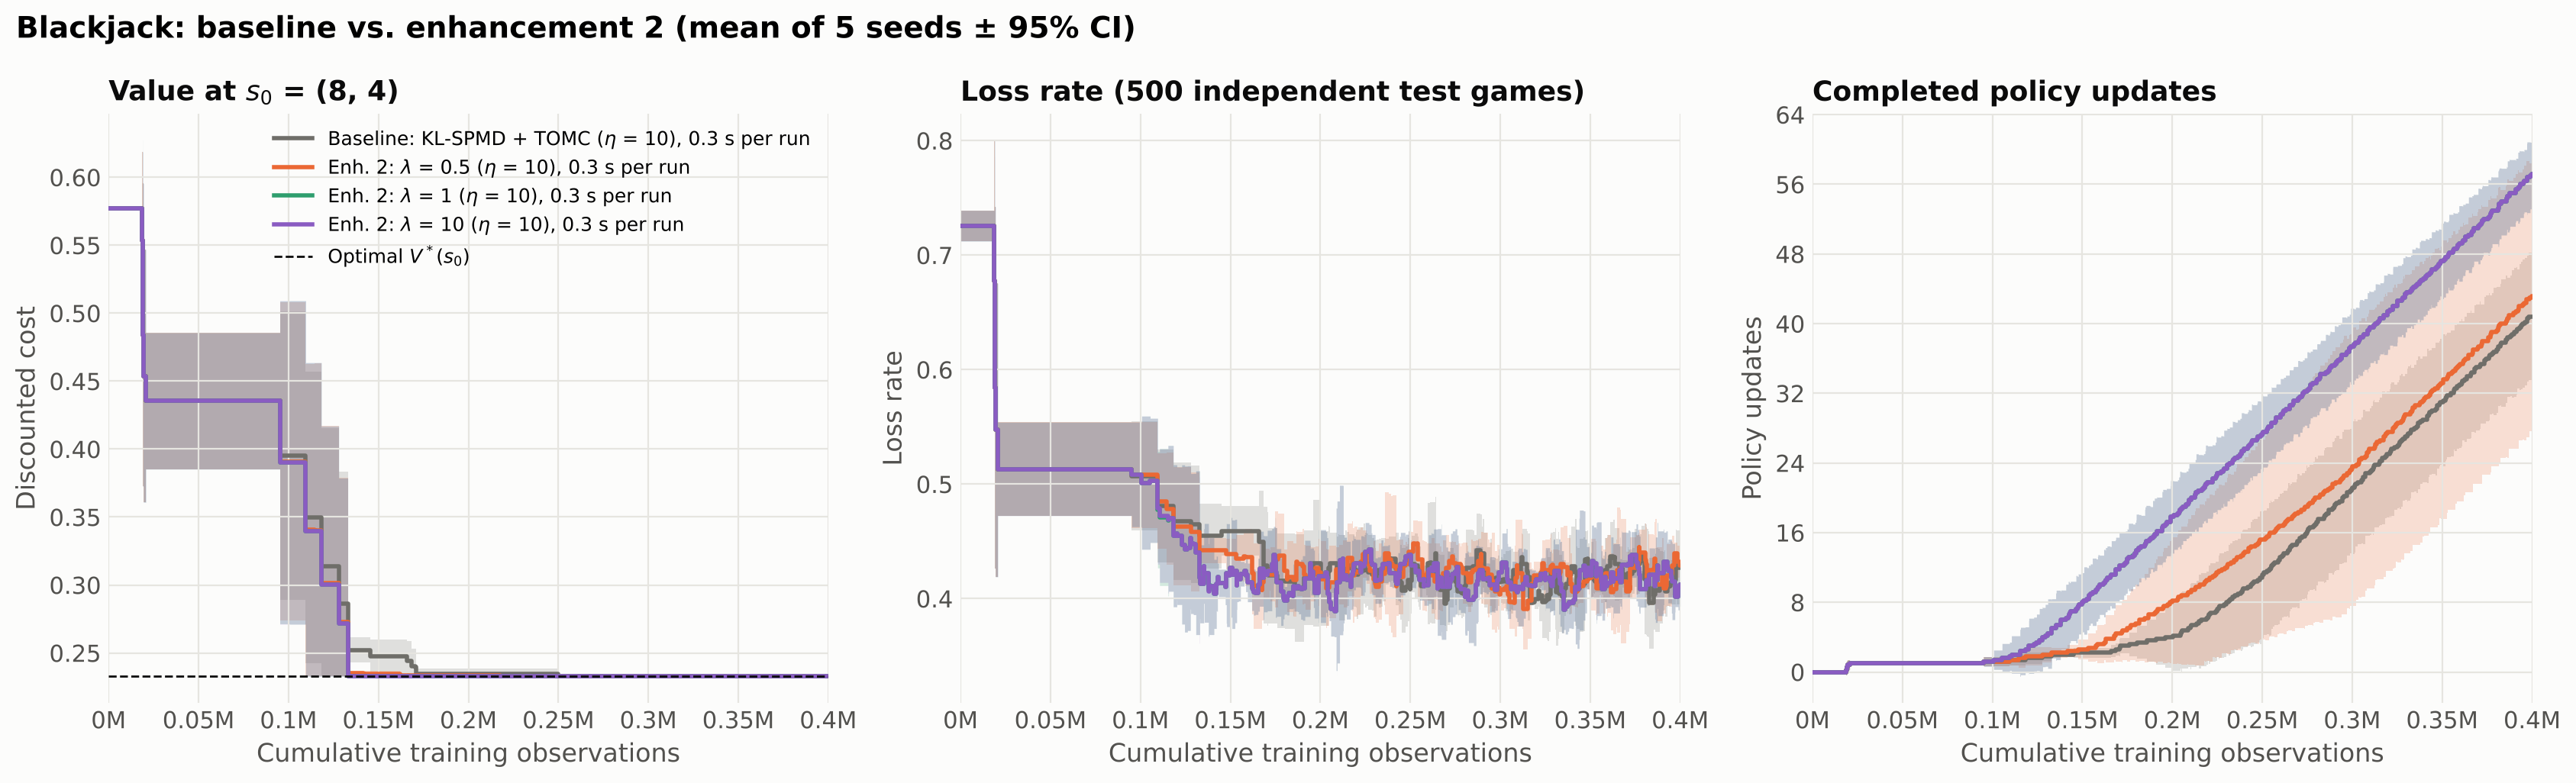

In [10]:
def apply_plot_style(large=False):
    plt.rcdefaults()
    plt.rcParams.update({
        "figure.facecolor": BACKGROUND, "axes.facecolor": BACKGROUND, "savefig.facecolor": BACKGROUND,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.spines.left": False, "axes.spines.bottom": False,
        "axes.grid": True, "grid.color": GRID_COLOR, "grid.linewidth": 0.8,
        "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
        "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
        "xtick.major.size": 0, "ytick.major.size": 0,
        "legend.frameon": False, "font.family": "DejaVu Sans",
        "font.size": 11, "axes.titlesize": 13, "axes.labelsize": 12, "legend.fontsize": 10.5,
    })
    if large:
        plt.rcParams.update({"font.size": 16, "axes.titlesize": 18, "axes.labelsize": 16,
                             "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14})


def plot_band(ax, points, curves, color, line_label, band_label=None, linewidth=2.0, lower=None):
    """Staircase mean across seeds with a shaded 95% confidence band.

    lower: a hard bound of the metric (V* for an exact value). The symmetric t-interval can
    cross it when seeds disagree (some converged, some not); the band is cut there.
    """
    mean, half_width = mean_ci(curves)
    low = mean - half_width if lower is None else np.maximum(mean - half_width, lower)
    ax.fill_between(points, low, mean + half_width, step="post",
                    color=color, alpha=0.2, linewidth=0, label=band_label)
    ax.step(points, mean, where="post", color=color, linewidth=linewidth, label=line_label)
    return mean, half_width


def save_figure(fig, name):
    FIGURES.mkdir(exist_ok=True)
    for suffix in ("png", "pdf"):
        fig.savefig(FIGURES / f"{name}.{suffix}", dpi=200, bbox_inches="tight")


def metric_curves(method_runs):
    """Aligned value, loss-rate and update curves for one method."""
    points = update_points(method_runs, SAMPLE_BUDGET)
    update_grid = update_points(method_runs, SAMPLE_BUDGET, key="update_samples")
    return {"points": points, "update_points": update_grid,
            "values": np.array([on_grid(run, points, "values")[:, REPORT_STATE] for run in method_runs]),
            "losses": np.array([on_grid(run, points, "loss_rate") for run in method_runs]),
            "updates": np.array([updates_on_grid(run, update_grid) for run in method_runs])}


millions = FuncFormatter(lambda x, _: f"{x / 1e6:g}M")
n_seeds = len(SEEDS)
base = metric_curves(baseline_runs)
enh = {lam: metric_curves(enh_runs[lam]) for lam in LAMBDA_CANDIDATES}
BASE_NAME = f"Baseline: KL-SPMD + TOMC ($\\eta$ = {BASE_ETA:g})"
ENH_NAMES = {lam: f"Enh. 2: $\\lambda$ = {lam:g} ($\\eta$ = {CONFIGS[lam]['eta']:g})" for lam in LAMBDA_CANDIDATES}

# Each entry: (points, curves, color, legend label); value labels carry the training time.
value_series = ([(base["points"], base["values"], BASELINE_COLOR, f"{BASE_NAME}, {BASE_SECONDS:.1f} s per run")]
                + [(enh[lam]["points"], enh[lam]["values"], LAMBDA_COLORS[lam],
                    f"{ENH_NAMES[lam]}, {ENH_SECONDS[lam]:.1f} s per run") for lam in LAMBDA_CANDIDATES])
loss_series = ([(base["points"], base["losses"], BASELINE_COLOR, BASE_NAME)]
               + [(enh[lam]["points"], enh[lam]["losses"], LAMBDA_COLORS[lam], ENH_NAMES[lam])
                  for lam in LAMBDA_CANDIDATES])
update_series = ([(base["update_points"], base["updates"], BASELINE_COLOR, BASE_NAME)]
                 + [(enh[lam]["update_points"], enh[lam]["updates"], LAMBDA_COLORS[lam], ENH_NAMES[lam])
                    for lam in LAMBDA_CANDIDATES])
TITLE_START = "Blackjack: baseline vs. enhancement 2"

# Overview: three panels side by side, both methods in every panel.
apply_plot_style()
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, series, lower in zip(axes, (value_series, loss_series, update_series), (v_star, None, None)):
    for points, curves, color, label in series:
        plot_band(ax, points, curves, color, label, lower=lower)
axes[0].axhline(v_star, color=INK, linewidth=1, linestyle="--", label="Optimal $V^*(s_0)$")
axes[0].set(title=f"Value at $s_0$ = {REPORT_LABEL}", ylabel="Discounted cost")
axes[1].set(title=f"Loss rate ({TEST_GAMES} independent test games)", ylabel="Loss rate")
axes[2].set(title="Completed policy updates", ylabel="Policy updates")
axes[2].yaxis.set_major_locator(MaxNLocator(integer=True))
for ax in axes:
    ax.set(xlabel="Cumulative training observations", xlim=(0, SAMPLE_BUDGET))
    ax.xaxis.set_major_formatter(millions)
axes[0].legend(loc="upper right", fontsize=9)
fig.suptitle(f"{TITLE_START} (mean of {n_seeds} seeds ± 95% CI)",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
save_figure(fig, "blackjack_enh2_results")
plt.show()

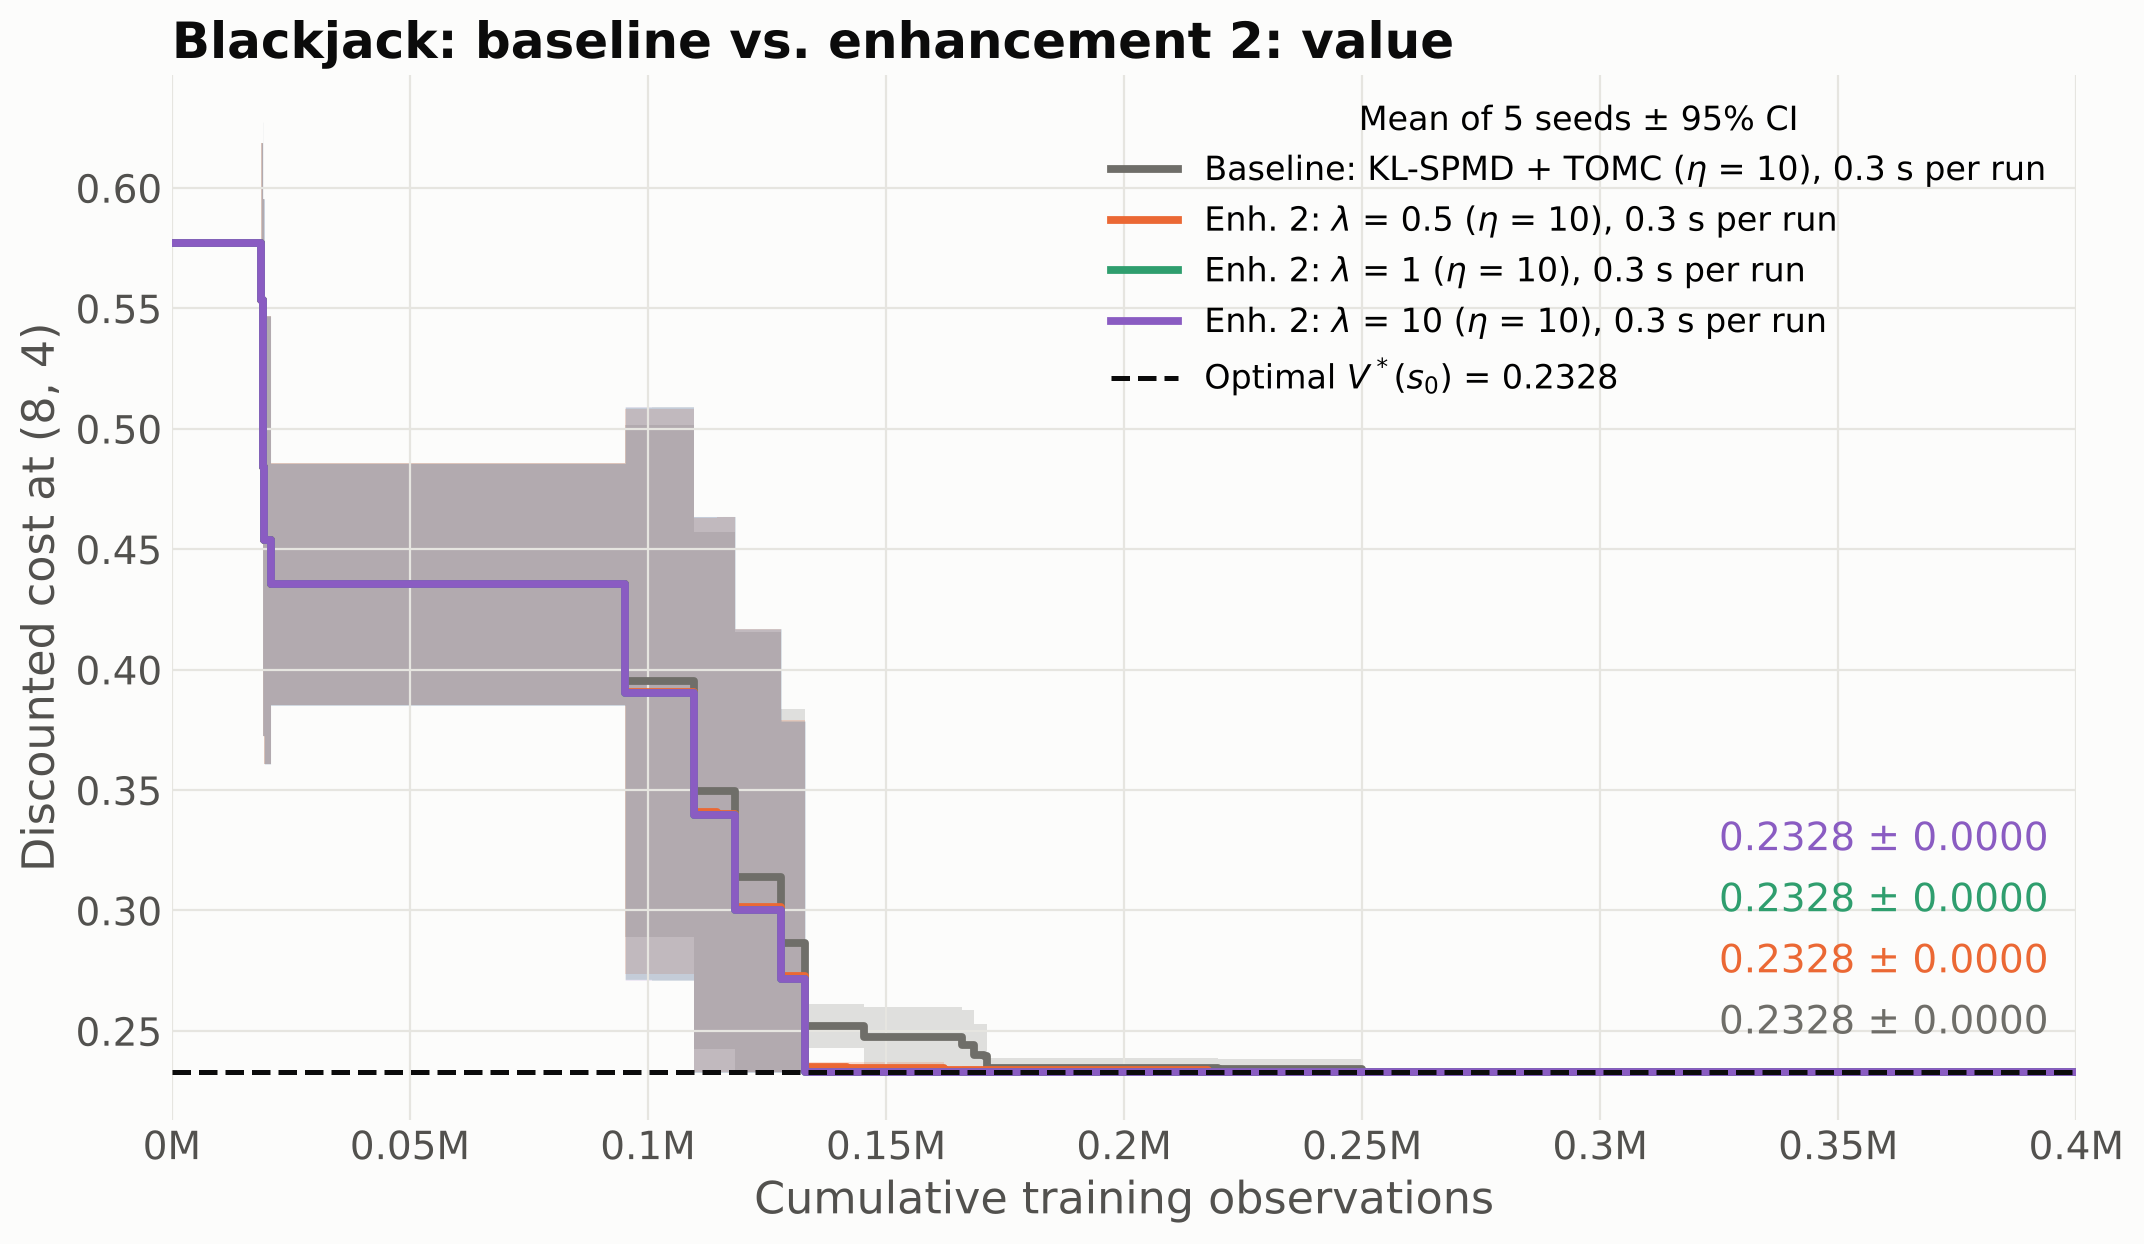

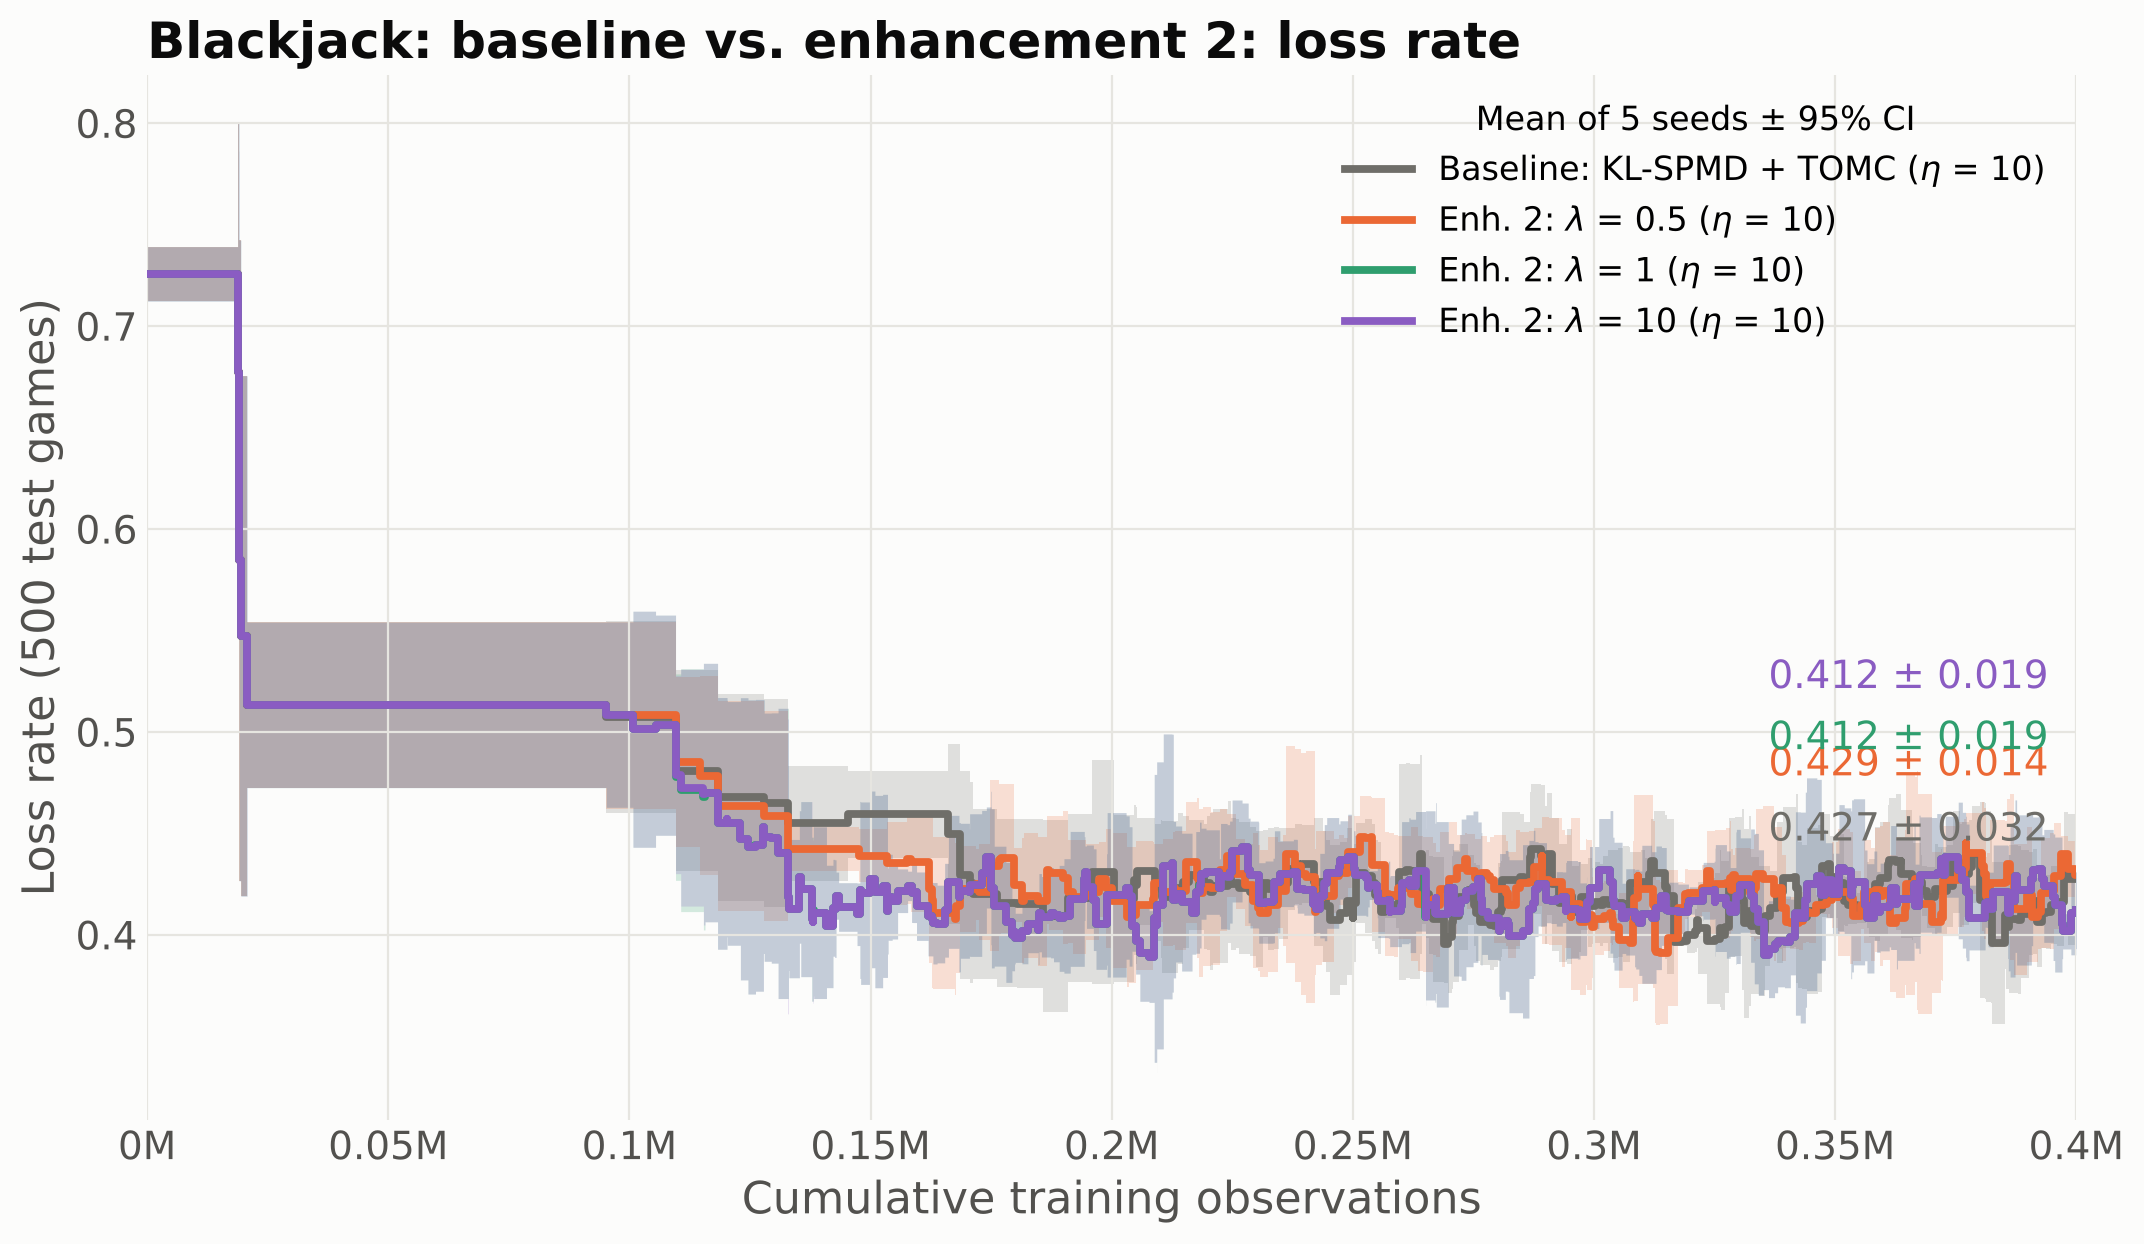

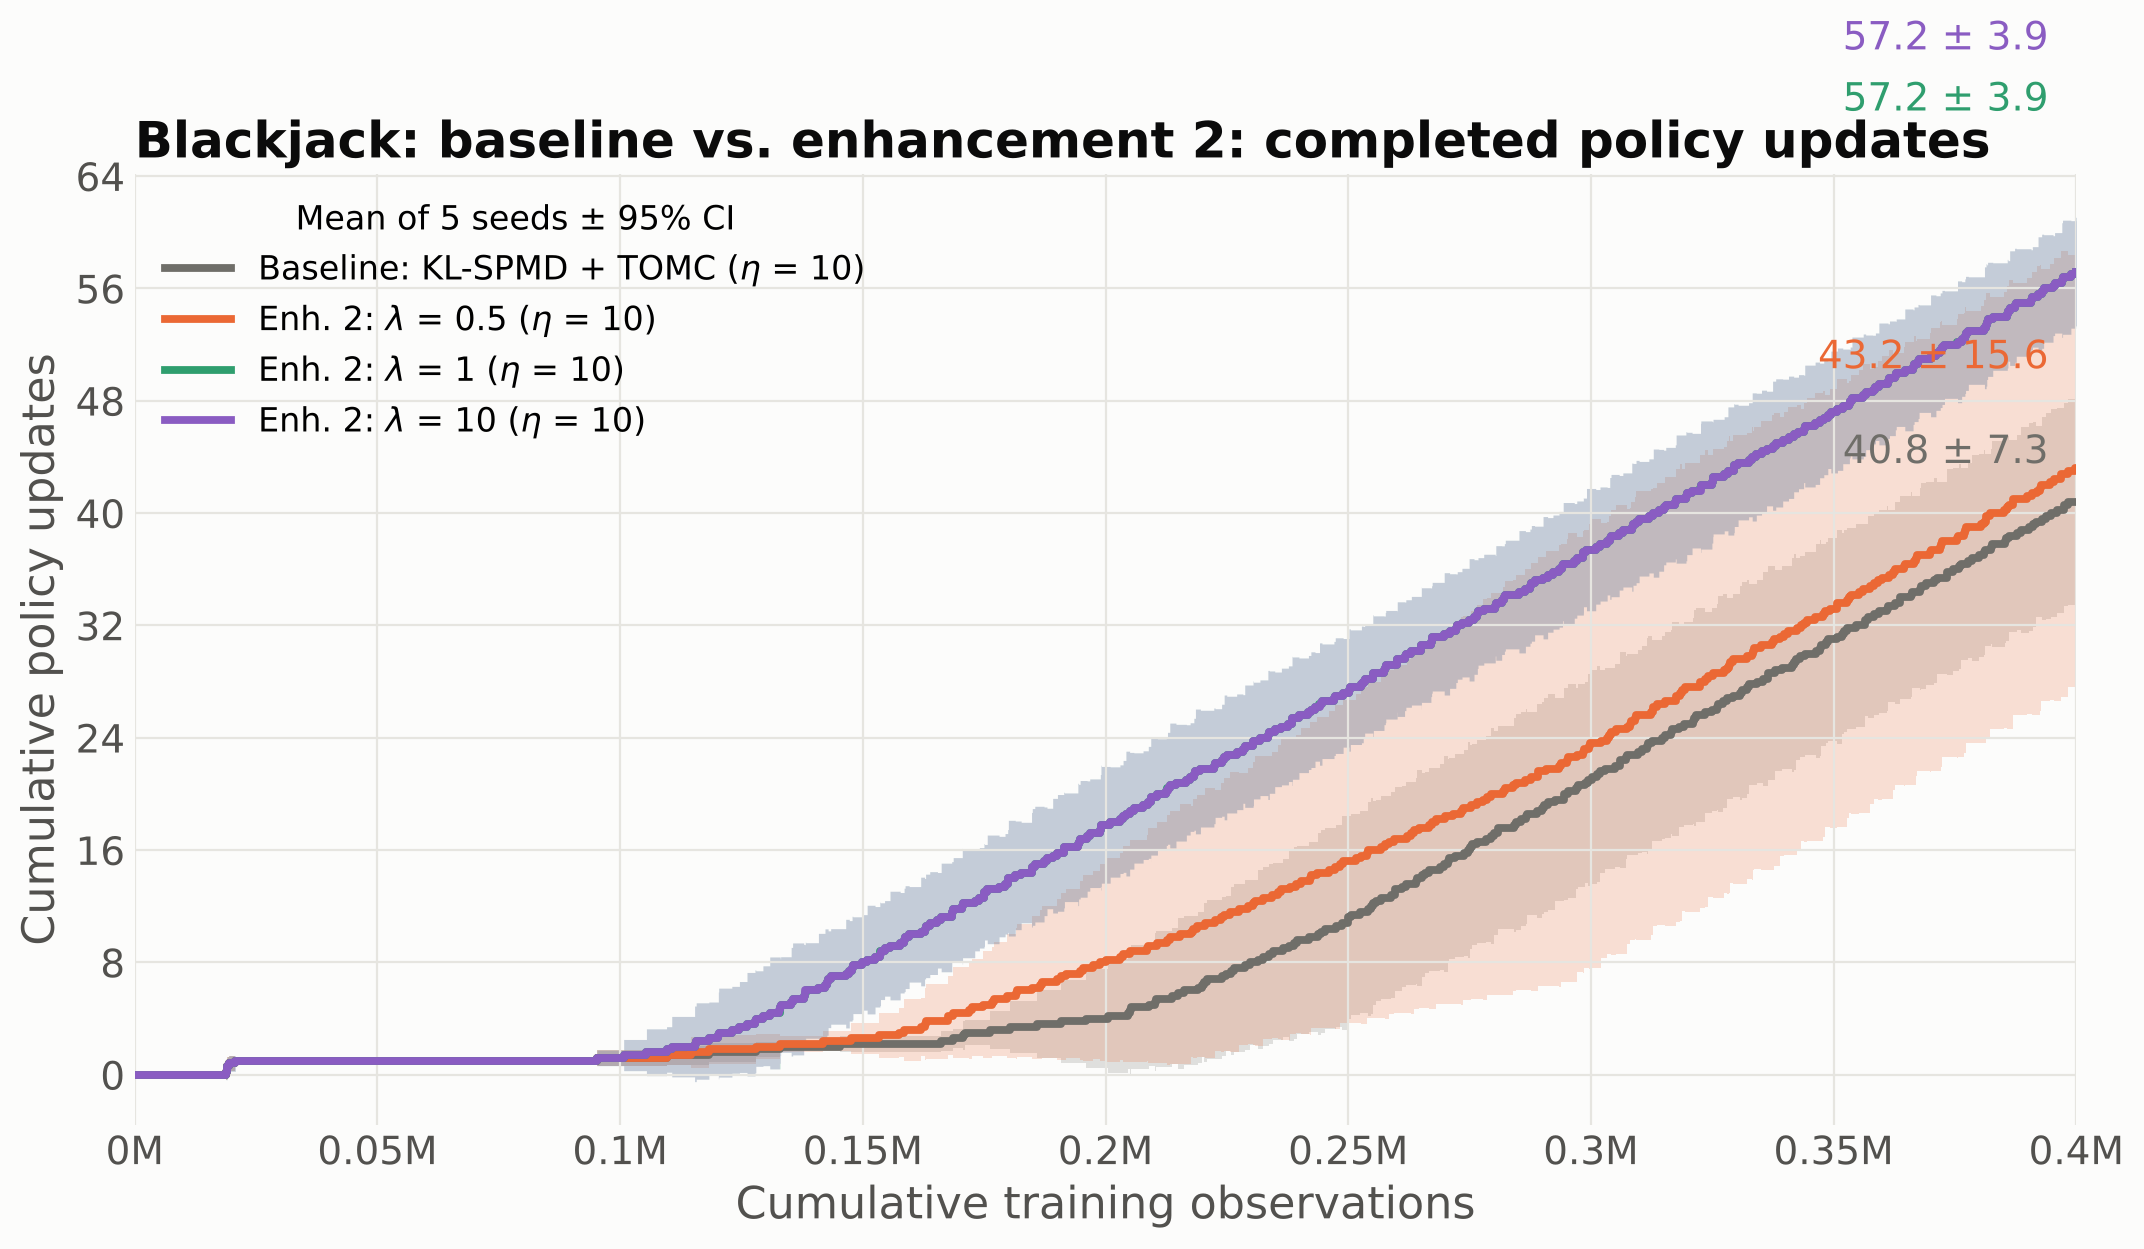

In [11]:
# Large slide figures, one per metric (same size and fonts as the other slide figures).
def slide_figure(series, title, ylabel, name, reference=None, reference_label=None,
                 value_format="{:.4f}", integer_axis=False, lower=None):
    """series: list of (points, curves, color, legend label), drawn with mean ± 95% CI."""
    apply_plot_style(large=True)
    fig, ax = plt.subplots(figsize=(11, 6.5))
    for index, (points, curves, color, label) in enumerate(series):
        mean, half_width = plot_band(ax, points, curves, color, label, linewidth=2.8, lower=lower)
        # End labels are stacked so two curves ending at the same height stay readable.
        ax.annotate(f"{value_format.format(mean[-1])} ± {value_format.format(half_width[-1])}",
                    (points[-1], mean[-1]), xytext=(-10, 14 + 22 * index), textcoords="offset points",
                    ha="right", color=color, fontsize=14)
    if reference is not None:
        ax.axhline(reference, color=INK, linewidth=1.8, linestyle="--", label=reference_label)
    ax.set(title=title, xlabel="Cumulative training observations", ylabel=ylabel,
           xlim=(0, SAMPLE_BUDGET))
    ax.xaxis.set_major_formatter(millions)
    if integer_axis:
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(loc="best", fontsize=12, title=f"Mean of {n_seeds} seeds ± 95% CI", title_fontsize=12)
    fig.tight_layout()
    save_figure(fig, name)
    plt.show()


slide_figure(value_series, f"{TITLE_START}: value", f"Discounted cost at {REPORT_LABEL}",
             "blackjack_enh2_value", reference=v_star,
             reference_label=f"Optimal $V^*(s_0)$ = {v_star:.4f}", lower=v_star)
slide_figure(loss_series, f"{TITLE_START}: loss rate", f"Loss rate ({TEST_GAMES} test games)",
             "blackjack_enh2_loss_rate", value_format="{:.3f}")
slide_figure(update_series, f"{TITLE_START}: completed policy updates", "Cumulative policy updates",
             "blackjack_enh2_updates", value_format="{:.1f}", integer_axis=True)

## 10b. Summary figure (2 x 2): value, estimate, loss rate, observations

1. Exact $V^{\pi_k}(s_0)$ against cumulative observations (band cut at $V^*$).
2. Sampled estimate $\widehat V_k(s_0)=\sum_a\pi_k(a\mid s_0)\widehat Q_k(s_0,a)$ against policy
   iteration $k$, from the raw $\widehat Q_k$ (never the momentum table $M_k$).
3. Loss rate in 500 independent test games against cumulative observations, with the
   optimal policy's exact loss probability.
4. Cumulative observations against policy iteration $k$ (completed batches only).
Mean of five seeds with 95% CIs; each legend entry gives the final mean ± half-width. Iteration
curves use the iterations completed by every seed. All methods complete a few dozen
iterations, so panels 2 and 4 use a linear iteration axis by default.

Optimal policy: exact loss probability = 0.4181


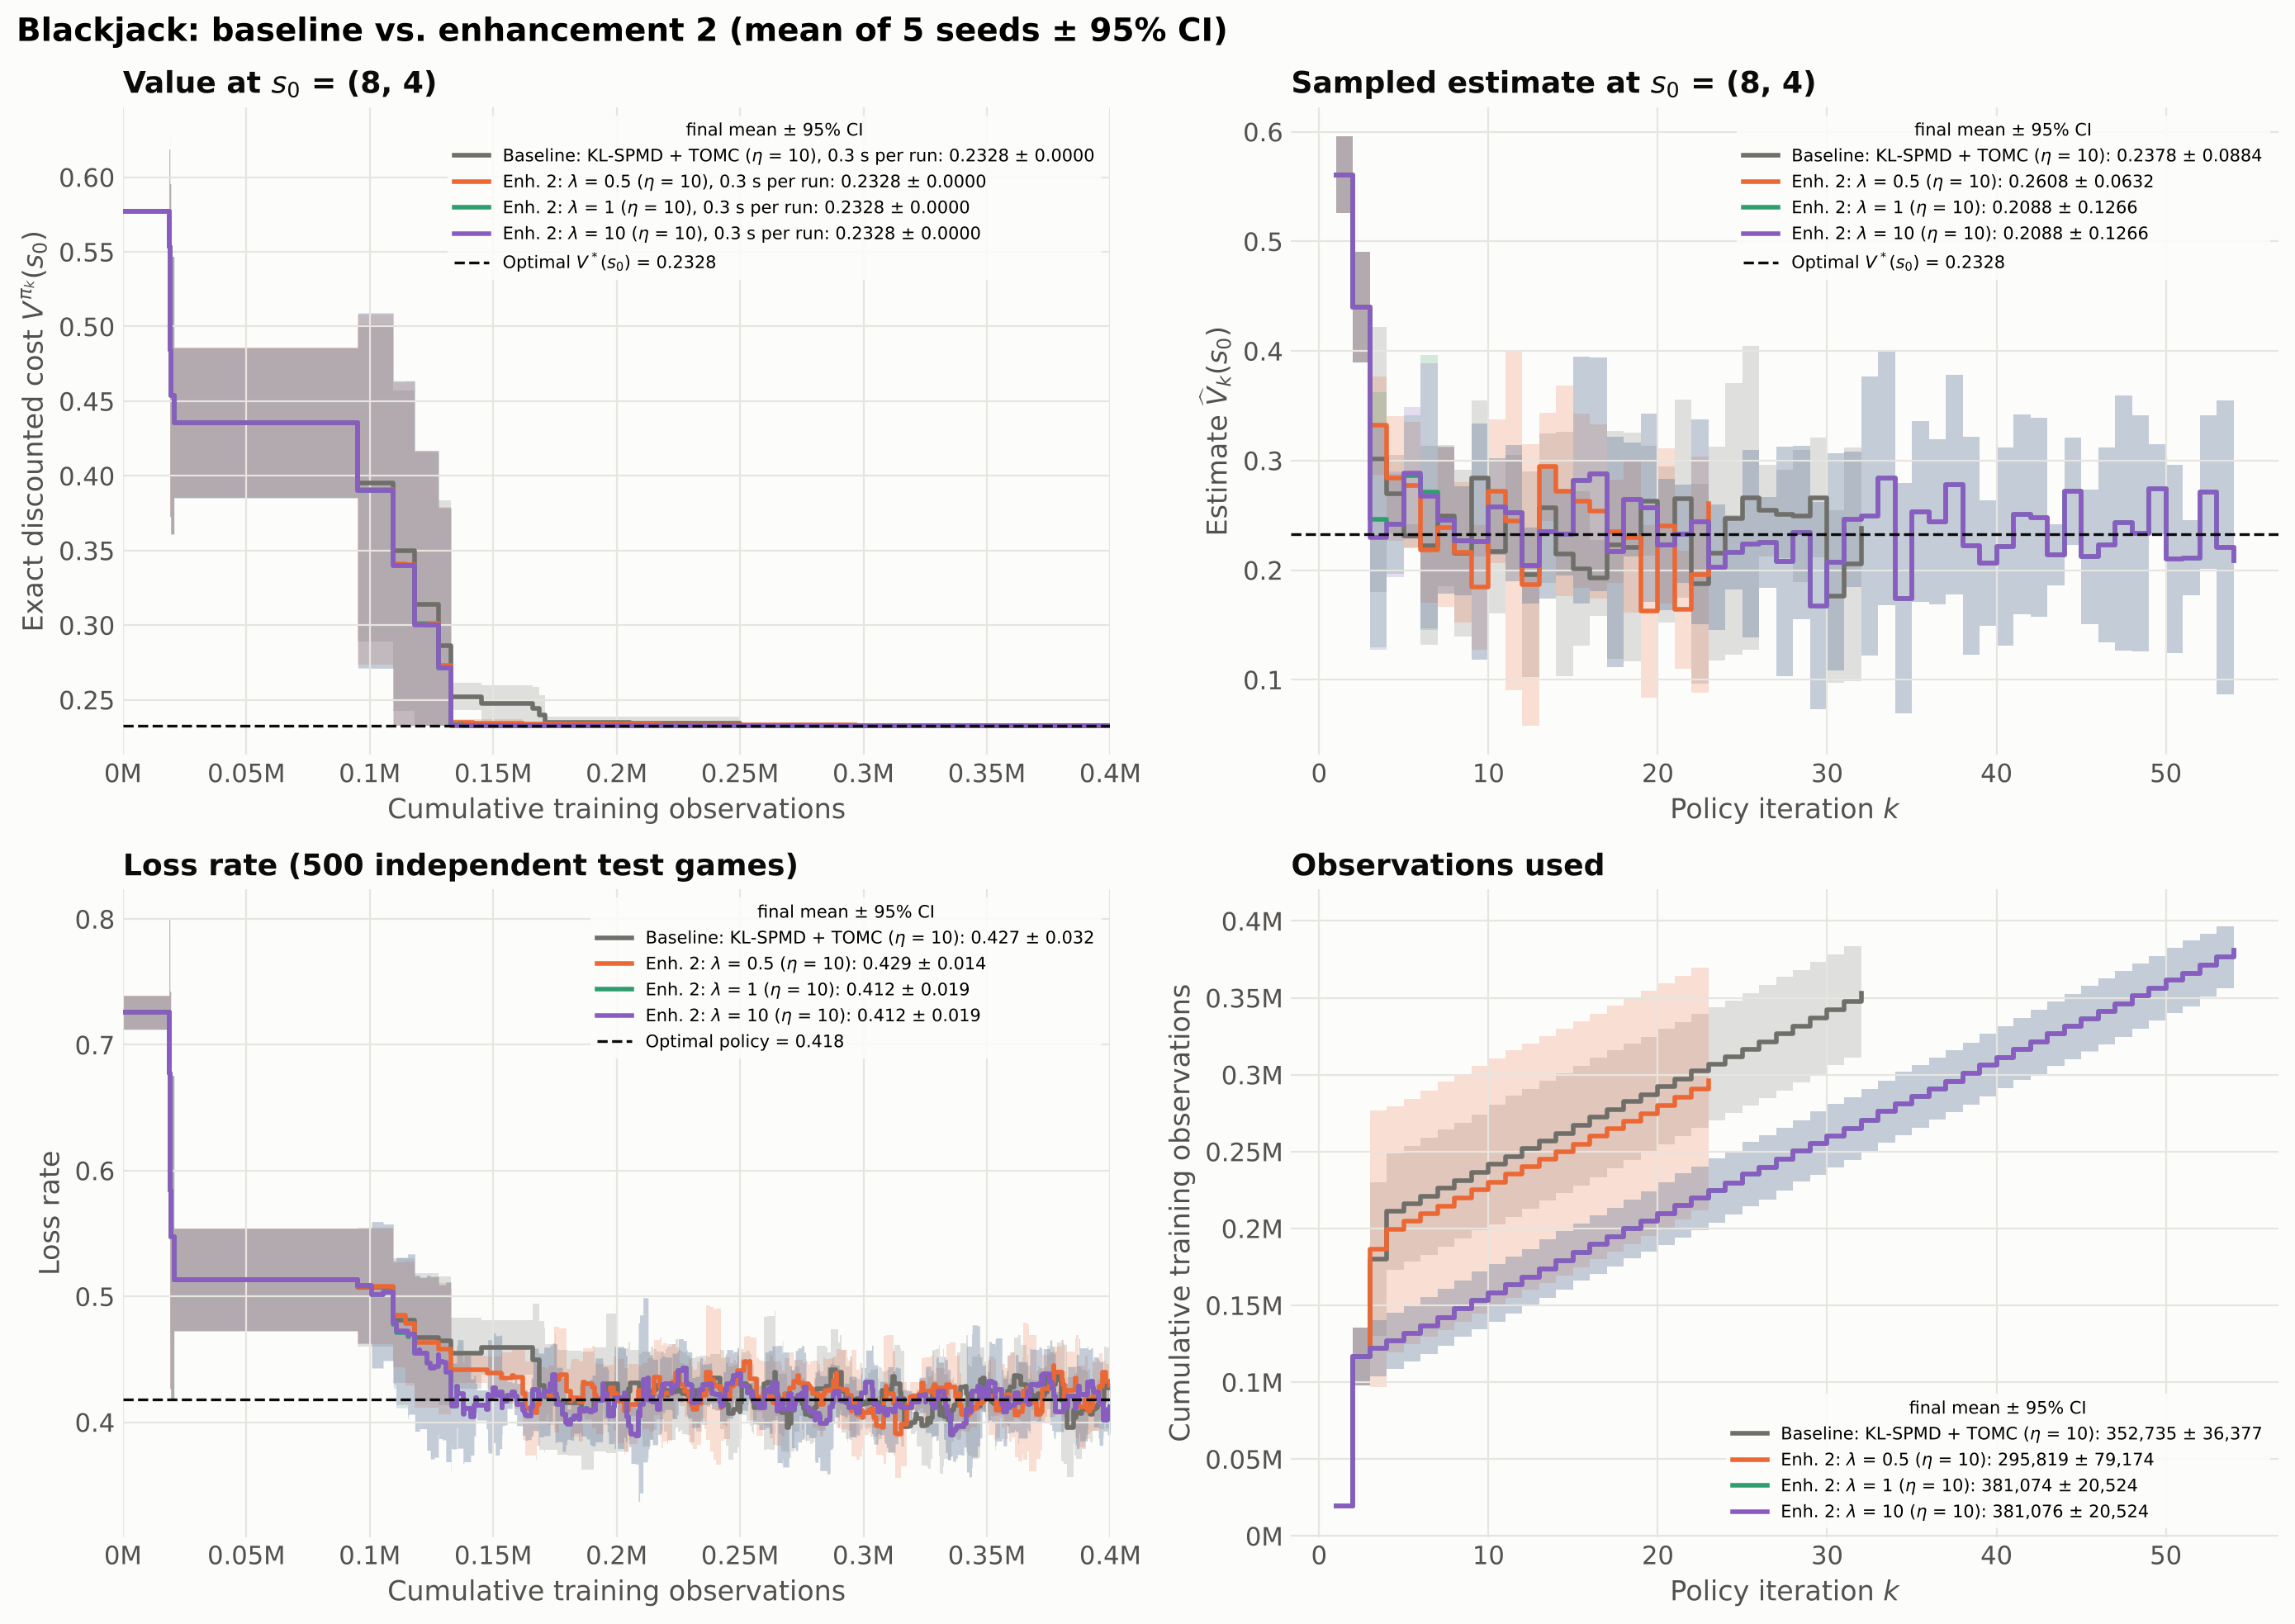

In [12]:
LOG_ITERATION_AXIS = False                # Set True for a logarithmic iteration axis in panels 2 and 4.


def exact_loss_probability(policy):
    """Exact probability that a freshly dealt hand is lost under `policy` (undiscounted)."""
    loss_now = np.zeros((N_STATES, N_ACTIONS))           # Loss on this action: lower total or bust.
    for dealer_card in DEALER_CARDS:
        dealer = dealer_final_distribution(dealer_card)
        for player_sum in PLAYER_SUMS:
            s = state2ID(player_sum, dealer_card)
            loss_now[s, STICK] = sum(prob for total, prob in dealer.items()
                                     if player_sum < total <= BUST_LIMIT)
            loss_now[s, HIT] = sum(player_sum + card > BUST_LIMIT for card in CARD_VALUES) / len(CARD_VALUES)
    P_pi = np.einsum("sa,sat->st", policy, P_exact)
    loss = np.linalg.solve(np.eye(N_STATES) - P_pi, np.sum(policy * loss_now, axis=1))
    start = np.zeros(N_STATES)                            # Deal: two player cards, one dealer card.
    for c1 in CARD_VALUES:
        for c2 in CARD_VALUES:
            for dealer_card in CARD_VALUES:
                start[state2ID(c1 + c2, dealer_card)] += 1 / len(CARD_VALUES) ** 3
    return float(start @ loss)


OPTIMAL_POLICY = np.eye(N_ACTIONS)[OPTIMAL_ACTIONS]
OPTIMAL_LOSS = exact_loss_probability(OPTIMAL_POLICY)
print(f"Optimal policy: exact loss probability = {OPTIMAL_LOSS:.4f}")


def common_prefix(arrays):
    """Stack per-seed arrays over the iterations every seed completed."""
    n = min(len(a) for a in arrays)
    return np.array([np.asarray(a, dtype=float)[:n] for a in arrays])


def iteration_series(key):
    """Per-method (iterations, curves, color, label) for an iteration-indexed metric."""
    series = []
    for method_key, name, method_runs, color in METHODS:
        if key == "estimate":                  # V-hat_k of iteration k = 1, 2, ...
            curves_k = common_prefix([run["estimate"] for run in method_runs])
        else:                                  # Cumulative observations after k iterations.
            curves_k = common_prefix([run["update_samples"][1:] for run in method_runs])
        series.append((np.arange(1, curves_k.shape[1] + 1), curves_k, color, name))
    return series


# Same method order and colors as the other figures.
METHODS = ([("baseline", BASE_NAME, baseline_runs, BASELINE_COLOR)]
           + [(lam, ENH_NAMES[lam], enh_runs[lam], LAMBDA_COLORS[lam]) for lam in LAMBDA_CANDIDATES])

panels = [
    (value_series, v_star, "{:.4f}", f"Value at $s_0$ = {REPORT_LABEL}",
     "Cumulative training observations", "Exact discounted cost $V^{\\pi_k}(s_0)$"),
    (iteration_series("estimate"), None, "{:.4f}", f"Sampled estimate at $s_0$ = {REPORT_LABEL}",
     "Policy iteration $k$", "Estimate $\\widehat V_k(s_0)$"),
    (loss_series, None, "{:.3f}", f"Loss rate ({TEST_GAMES} independent test games)",
     "Cumulative training observations", "Loss rate"),
    (iteration_series("observations"), None, "{:,.0f}", "Observations used",
     "Policy iteration $k$", "Cumulative training observations"),
]

apply_plot_style()
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for index, (ax, (series, lower, value_format, title, xlabel, ylabel)) in enumerate(zip(axes.flat, panels)):
    for points, method_curves, color, label in series:
        # Final mean ± 95% half-width goes into the legend (five curves: floating labels collide).
        final_mean, final_half = mean_ci(method_curves)
        final = f"{value_format.format(final_mean[-1])} ± {value_format.format(final_half[-1])}"
        mean, _ = plot_band(ax, points, method_curves, color, f"{label}: {final}", lower=lower)
        if len(points) <= 10:                  # Very short curves: mark each iteration.
            ax.plot(points, mean, "o", color=color, markersize=4)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    if index in (0, 2):
        ax.set_xlim(0, SAMPLE_BUDGET)
        ax.xaxis.set_major_formatter(millions)
    elif LOG_ITERATION_AXIS:
        ax.set_xscale("log")
for ax in (axes[0, 0], axes[0, 1]):
    ax.axhline(v_star, color=INK, linewidth=1.2, linestyle="--", label=f"Optimal $V^*(s_0)$ = {v_star:.4f}")
axes[1, 0].axhline(OPTIMAL_LOSS, color=INK, linewidth=1.2, linestyle="--",
                   label=f"Optimal policy = {OPTIMAL_LOSS:.3f}")
axes[1, 1].yaxis.set_major_formatter(millions)
for ax in axes.flat:
    ax.legend(loc="best", fontsize=7.5, title="final mean ± 95% CI", title_fontsize=7.5,
              frameon=True, facecolor=BACKGROUND, edgecolor="none", framealpha=0.9)
fig.suptitle(f"{TITLE_START} (mean of {n_seeds} seeds ± 95% CI)",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
save_figure(fig, "blackjack_enh2_summary_2x2")
plt.show()

## 11. Tuning summary

Each cell is the exact gap at (8, 4) after `TUNING_BUDGET` observations (log color scale,
darker is worse), with its overall rank and number of completed updates. Each row's selected
eta is outlined in that lambda's plot color.

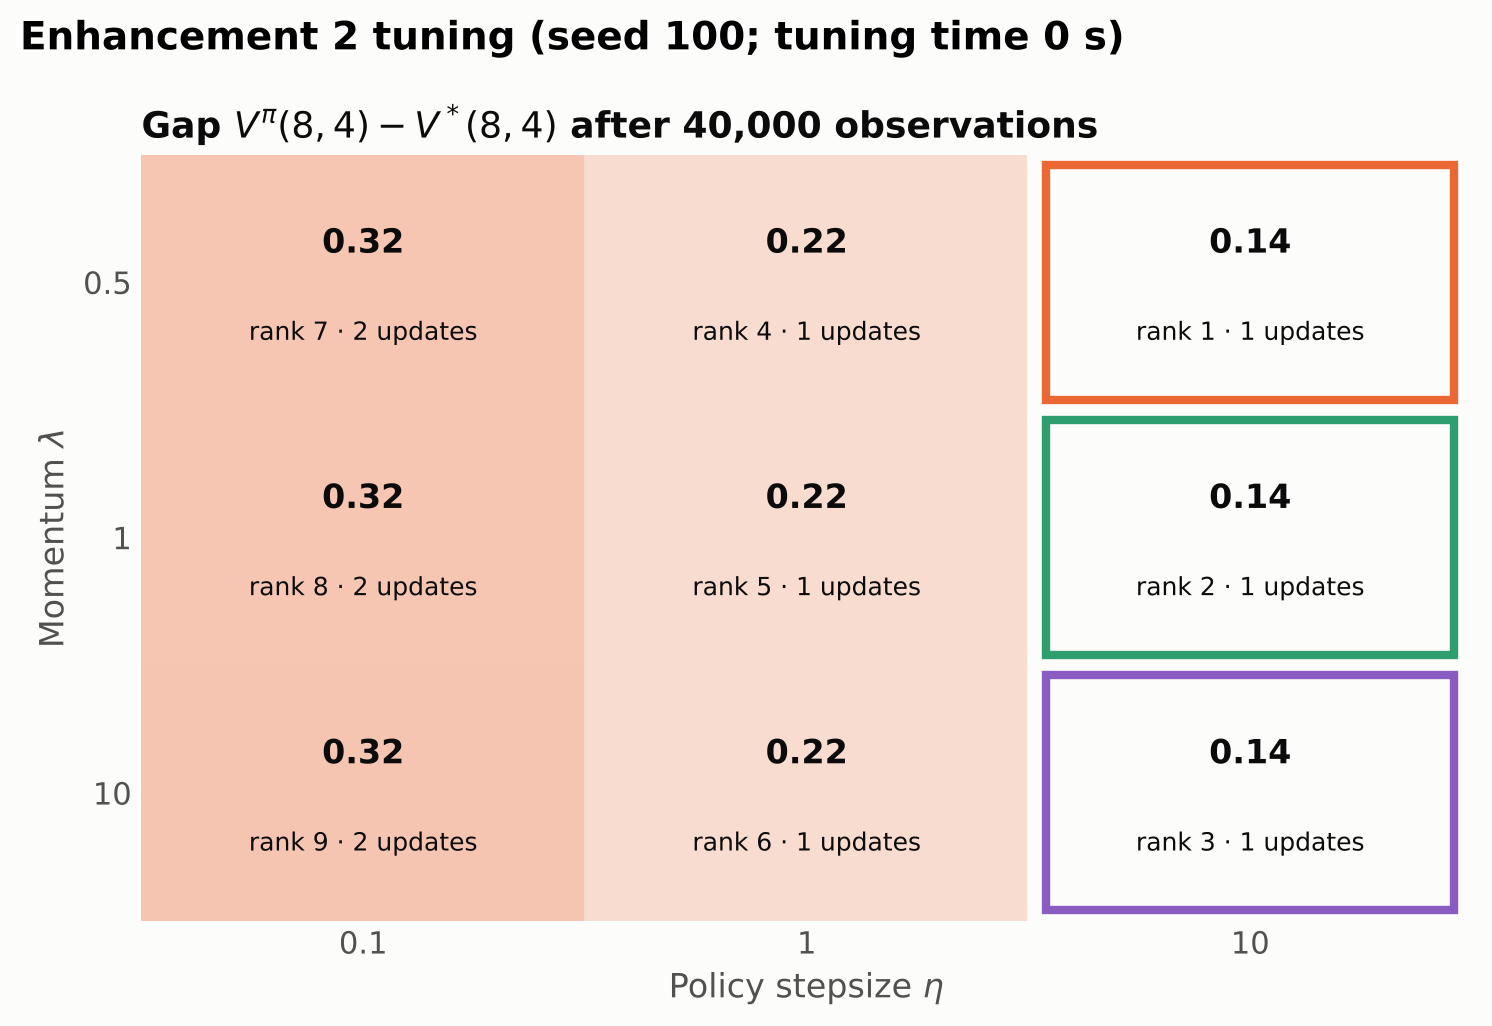

In [13]:
apply_plot_style()
fig, ax = plt.subplots(figsize=(7.5, 5.2))
cmap = LinearSegmentedColormap.from_list("enh2", [BACKGROUND, ENH_COLOR])
floor = 1e-6
gaps = np.maximum(tuning["gap_at_reference"].to_numpy(), floor)
norm = LogNorm(vmin=gaps.min(), vmax=max(gaps.max(), 10 * gaps.min()))
for i, lam in enumerate(LAMBDA_CANDIDATES):
    for j, eta in enumerate(ETA_CANDIDATES):
        row = tuning[(tuning["lambda"] == lam) & (tuning["eta"] == eta)].iloc[0]
        gap = max(row["gap_at_reference"], floor)
        ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, color=cmap(norm(gap))))
        text_color = "white" if norm(gap) > 0.6 else INK
        ax.text(j, i - 0.15, f"{row['gap_at_reference']:.2g}", ha="center", va="center",
                fontsize=12, color=text_color, fontweight="bold")
        ax.text(j, i + 0.2, f"rank {int(row['rank'])} · {int(row['policy_updates'])} updates",
                ha="center", va="center", fontsize=9, color=text_color)
        if eta == CONFIGS[lam]["eta"]:
            ax.add_patch(Rectangle((j - 0.46, i - 0.46), 0.92, 0.92, fill=False,
                                   edgecolor=LAMBDA_COLORS[lam], linewidth=3))
ax.set(xlim=(-0.5, 2.5), ylim=(2.5, -0.5),
       xticks=range(3), xticklabels=[f"{eta:g}" for eta in ETA_CANDIDATES],
       yticks=range(3), yticklabels=[f"{lam:g}" for lam in LAMBDA_CANDIDATES],
       xlabel="Policy stepsize $\\eta$", ylabel="Momentum $\\lambda$",
       title=f"Gap $V^{{\\pi}}{REPORT_LABEL} - V^*{REPORT_LABEL}$ after {TUNING_BUDGET:,} observations")
ax.grid(False)
fig.suptitle(f"Enhancement 2 tuning (seed {TUNING_SEED}; tuning time {tuning_seconds:.0f} s)",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
save_figure(fig, "blackjack_enh2_tuning")
plt.show()

## 12. Comparison table at the full budget

In [14]:
comparison_rows = []
for name, settings, method_runs in (
        [("Baseline: KL-SPMD + TOMC", f"eta = {BASE_ETA:g}", baseline_runs)]
        + [("Enh. 2: momentum KL-SPMD + TOMC", f"eta = {CONFIGS[lam]['eta']:g}, lambda = {lam:g}",
            enh_runs[lam]) for lam in LAMBDA_CANDIDATES]):
    metrics = pd.DataFrame([final_metrics(run) for run in method_runs])
    comparison_rows.append({
        "method": name, "settings": settings,
        "gap_at_reference": format_mean_ci(metrics["gap_at_reference"]),
        "mean_gap_all_states": format_mean_ci(metrics["mean_gap_all_states"]),
        "loss_rate": format_mean_ci(metrics["loss_rate"], 3),
        "policy_updates": format_mean_ci(metrics["policy_updates"], 1),
        "seconds_per_run": format_mean_ci(metrics["train_seconds"], 1)})
print(f"All methods at {SAMPLE_BUDGET:,} training observations (mean ± 95% CI over {n_seeds} seeds):")
print(pd.DataFrame(comparison_rows).to_string(index=False))
print(f"Tuning time, reported separately: Enhancement 2 ({len(tuning)} configurations) "
      f"{tuning_seconds:.1f} s; baseline ({len(ETA_CANDIDATES)} stepsizes) {baseline_tuning_seconds:.1f} s.")

All methods at 400,000 training observations (mean ± 95% CI over 5 seeds):
                         method               settings gap_at_reference mean_gap_all_states     loss_rate policy_updates seconds_per_run
       Baseline: KL-SPMD + TOMC               eta = 10  0.0000 ± 0.0000    -0.0000 ± 0.0000 0.427 ± 0.032     40.8 ± 7.3       0.3 ± 0.0
Enh. 2: momentum KL-SPMD + TOMC eta = 10, lambda = 0.5  0.0000 ± 0.0000    -0.0000 ± 0.0000 0.429 ± 0.014    43.2 ± 15.6       0.3 ± 0.0
Enh. 2: momentum KL-SPMD + TOMC   eta = 10, lambda = 1  0.0000 ± 0.0000    -0.0000 ± 0.0000 0.412 ± 0.019     57.2 ± 3.9       0.3 ± 0.1
Enh. 2: momentum KL-SPMD + TOMC  eta = 10, lambda = 10  0.0000 ± 0.0000    -0.0000 ± 0.0000 0.412 ± 0.019     57.2 ± 3.9       0.3 ± 0.0
Tuning time, reported separately: Enhancement 2 (9 configurations) 0.3 s; baseline (3 stepsizes) 0.1 s.


## 13. Learned policy of the first seed

P(HIT) of the final policy of the lambda with the smallest mean gap at (8, 4), next to the
optimal action.

In [15]:
best_lam = min(LAMBDA_CANDIDATES, key=lambda l: np.mean([final_metrics(r)["gap_at_reference"]
                                                         for r in enh_runs[l]]))
final = enh_runs[best_lam][0]["final_policy"]
policy_table = pd.DataFrame(
    [[f"{final[state2ID(p, d), HIT]:.2f} ({'SH'[OPTIMAL_ACTIONS[state2ID(p, d)]]})"
      for d in DEALER_CARDS] for p in PLAYER_SUMS],
    index=[f"sum {p}" for p in PLAYER_SUMS], columns=[f"dealer {d}" for d in DEALER_CARDS])
print(f"Seed {SEEDS[0]}: final P(HIT) for lambda = {best_lam:g}, optimal action in brackets")
print(policy_table.to_string())

Seed 0: final P(HIT) for lambda = 0.5, optimal action in brackets
        dealer 2  dealer 3  dealer 4  dealer 5
sum 4   1.00 (H)  1.00 (H)  1.00 (H)  1.00 (H)
sum 5   1.00 (H)  1.00 (H)  1.00 (H)  1.00 (H)
sum 6   1.00 (H)  1.00 (H)  1.00 (H)  1.00 (H)
sum 7   1.00 (H)  1.00 (H)  1.00 (H)  1.00 (H)
sum 8   1.00 (H)  1.00 (H)  1.00 (H)  1.00 (H)
sum 9   0.00 (S)  0.00 (S)  0.00 (S)  0.00 (S)
sum 10  0.00 (S)  0.00 (S)  0.00 (S)  0.00 (S)
sum 11  0.00 (S)  0.00 (S)  0.00 (S)  0.00 (S)
